# M1 BHE 2024-2025 "Informatics & Statistics" R Exam 

Subject: Alzheimer's disease and treatment

authors: Matthias Grenié & Chanidapa Winalai

## Instructions

The exam duration is **one hour**.  
You will have to handout the **paper version** of the exam and this will be the base of the grading.  
So don't forget to report your results on your sheet.  
The goal of this file is to have a framework to answer your exam questions.  

For this exam, **all documents are allowed** (including all previous notebooks), fact sheets/information sheets you may have prepared.  
What is not allowed: browsing on the internet in general and using conversational AIs.

For the grading, your answers must be complete but there is no need to give the code you typed unless otherwise specified.  
Show your work, including formulas and calculations where appropriate. Interpret all results in the context of Alzheimer's disease research and potential clinical implications.
Also note that the bonus questions are additional to the rest of the exam, don't forget them as you

**Note about α threshold**: For all statistical tests, use a **significance level of α = 0.03**.


## Background

Alzheimer's disease (AD) is a progressive neurodegenerative disorder that affects millions of people worldwide, primarily older adults. It is the most common cause of dementia, characterized by a decline in cognitive function, memory loss, and changes in behavior and personality. The disease is associated with the accumulation of abnormal protein deposits in the brain: amyloid-beta plaques and tau tangles. Despite decades of research, the exact causes of Alzheimer's disease remain unclear, and current treatments only manage symptoms without stopping or reversing the disease progression. The complex interplay between genetic factors, environmental influences, and lifestyle choices in the development and progression of AD makes it a challenging subject for researchers. Understanding the risk factors, early biomarkers, and potential therapeutic targets is crucial for developing more effective diagnostic tools and treatments for this devastating condition.

This dataset comes from a fictional longitudinal study investigating potential risk factors and treatment efficacy in Alzheimer's disease (AD). The study enrolled 200 participants, aged 50-90, with varying degrees of cognitive impairment. Researchers collected data on key AD biomarkers, genetic risk factors, and cognitive function. The APOE4 gene, a known risk factor for AD, was of particular interest, with participants categorized by their number of APOE4 alleles (0, 1, or 2). Cognitive function was assessed using a standardized test, yielding scores from 0-30, with higher scores indicating better cognitive performance. Brain volume measurements were included to track potential neurodegeneration. Cerebrospinal fluid (CSF) levels of amyloid-beta and tau proteins, both implicated in AD pathology, were measured. The study also evaluated two potential drug treatments (Drug A and Drug B) against a placebo, with follow-up assessments conducted at 6, 12, 18, and 24 months. This comprehensive dataset aims to shed light on the complex interplay between genetic predisposition, biomarkers, and treatment responses in Alzheimer's disease progression, potentially informing future diagnostic and therapeutic strategies.

## Dataset structure

This dataset contains 200 rows and 10 columns.

- `patient_id`: Unique identifier for each patient,
- `age`: Patient's age in years,
- `sex`: Patient's biological sex (`"male"`/`"female"`),
- `apoe4_status`: Number of APOE4 alleles (`0`, `1`, or `2`),
- `cognitive_score`: Score on a cognitive assessment (0 to 30, higher is better),
- `brain_volume`: Total brain volume in cm³,
- `amyloid_beta`: Levels of amyloid-beta protein in cerebrospinal fluid (CSF),
- `tau_protein`: Levels of tau protein in CSF,
- `treatment`: Treatment group (`"placebo"`, `"drug_a"`, or `"drug_b"`),
- `months_followup`: Duration of follow-up (6, 12, 18, or 24 months).

## Load data

In [1]:
study = read.csv("data/alzheimers_study_data.csv", header = TRUE)
head(study)

,patient_id,age,sex,apoe4_status,cognitive_score,brain_volume,amyloid_beta,tau_protein,treatment,months_followup
,<int>,<int>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>
1,1,59,male,0,17.36,970.91,37.07,47.37,drug_b,18
2,2,67,female,0,23.67,883.37,51.89,50.98,drug_a,24
3,3,59,male,2,17.76,984.40,32.87,77.98,drug_a,12
4,4,76,female,2,15.28,1030.97,44.76,82.69,drug_a,24
5,5,70,male,1,30.00,1070.05,44.75,43.88,placebo,12
6,6,62,female,1,23.53,961.58,39.74,59.92,drug_a,6


## Questions

**Question 1**. (1 point)  
Calculate the mean and standard deviation of `cognitive_score` for the entire dataset. What do these values tell us about the cognitive function of the study population?   

In [2]:
# Mean
mean(study$cognitive_score)

# sd
sd(study$cognitive_score)

# Answer: We see that our population scores a 21 over 30, with an sd of 5.
# This means that our study population doesn't seem to have the best cognitive score
# (=30, but we don't have the whole population to compare it to).
# Also, given the sd = 5, it means that, assuming a normal distribution, we have 96% of our distribution is between 11 and 30, so there is a huge variation.


[1] 21.53216

[1] 4.896695

**Question 2**. (2 points)  
Is there a significant difference in `cognitive_score` between males and females? Perform an appropriate statistical test, state your hypotheses, and interpret the results in the context of Alzheimer's disease research.  

In [3]:
# First we want to compare the average cognitive scores between men and women.
# We want to perform Student's t-test.
# First we need to check if there are enough samples
table(study$sex)
# N > 30 -> no need to check normality
# Second, equality of variances
# H0: Both variances are equal
# H1: Both variances are different
var.test(study$cognitive_score[study$sex == "male"], study$cognitive_score[study$sex == "female"])
#  We see p = 0.82 >>> alpha = 0.03, so we can't reject H0, and as such both variances are equal

# Then we perform Student's t-test
# H0: Both avg scores of male and female are equal
# H1: The avg cognitive scores are different
t.test(study$cognitive_score[study$sex == "male"], study$cognitive_score[study$sex == "female"], var.equal = TRUE)

# We observe p = 0.84 >>> 0.03, so we can't reject H0, and as such we don't observe a difference in cognitive scores between men and women.
# This means that, at our cohort level, we don't see a difference between men and women cognitive abilities in patients with AD


female   male 
    88    111 


	F test to compare two variances

data:  study$cognitive_score[study$sex == "male"] and study$cognitive_score[study$sex == "female"]
F = 1.2187, num df = 110, denom df = 87, p-value = 0.3371
alternative hypothesis: true ratio of variances is not equal to 1
95 percent confidence interval:
 0.8130253 1.8096098
sample estimates:
ratio of variances 
          1.218702 



	Two Sample t-test

data:  study$cognitive_score[study$sex == "male"] and study$cognitive_score[study$sex == "female"]
t = -0.020348, df = 197, p-value = 0.9838
alternative hypothesis: true difference in means is not equal to 0
95 percent confidence interval:
 -1.396073  1.367558
sample estimates:
mean of x mean of y 
 21.52586  21.54011 


**Question 3**. (2 points)  
Calculate the median and interquartile range of `amyloid_beta` levels for patients with `apoe4_status` of 0, 1, and 2.  
What do these descriptive statistics suggest about the relationship between APOE4 and amyloid-beta in Alzheimer's disease?  

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  17.43   29.55   37.50   37.93   46.18   71.92 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  15.77   33.59   40.05   38.73   44.75   56.70 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  20.04   36.18   45.66   44.07   50.91   65.36 

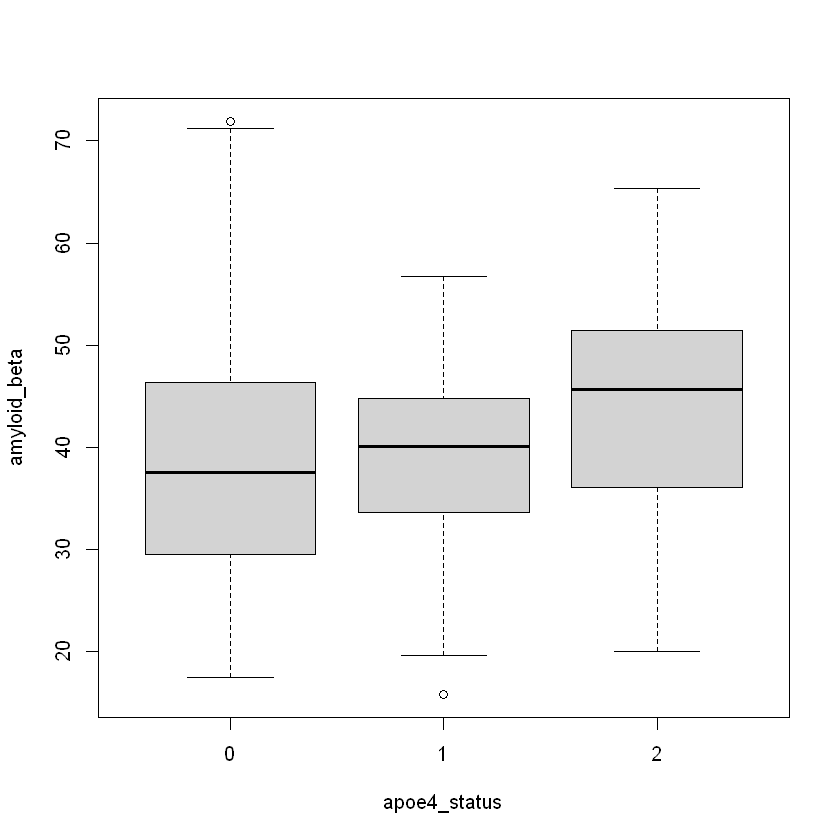

In [4]:
summary(study$amyloid_beta[study$apoe4_status == 0])
summary(study$amyloid_beta[study$apoe4_status == 1])
summary(study$amyloid_beta[study$apoe4_status == 2])

boxplot(amyloid_beta ~ apoe4_status, data = study)

# We see that the median increases with more alleles of APOE4 while the interquartile range stays somewhat stable around it.

**Question 4**. (2 points)  
Conduct a one-way ANOVA to compare the mean `cognitive_score` among the three treatment groups (placebo, drug A, drug B). State your hypotheses and interpret the results in terms of potential treatment effects. 


	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "placebo"]
W = 0.97837, p-value = 0.2932



	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "drug_a"]
W = 0.96361, p-value = 0.063



	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "drug_b"]
W = 0.97665, p-value = 0.215



	Bartlett test of homogeneity of variances

data:  cognitive_score by treatment
Bartlett's K-squared = 7.8072, df = 2, p-value = 0.02017



	Kruskal-Wallis rank sum test

data:  cognitive_score by treatment
Kruskal-Wallis chi-squared = 11.035, df = 2, p-value = 0.004015



	Pairwise comparisons using Wilcoxon rank sum test with continuity correction 

data:  study$cognitive_score and study$treatment 

        drug_a drug_b
drug_b  0.1489 -     
placebo 0.1404 0.0029

P value adjustment method: holm 

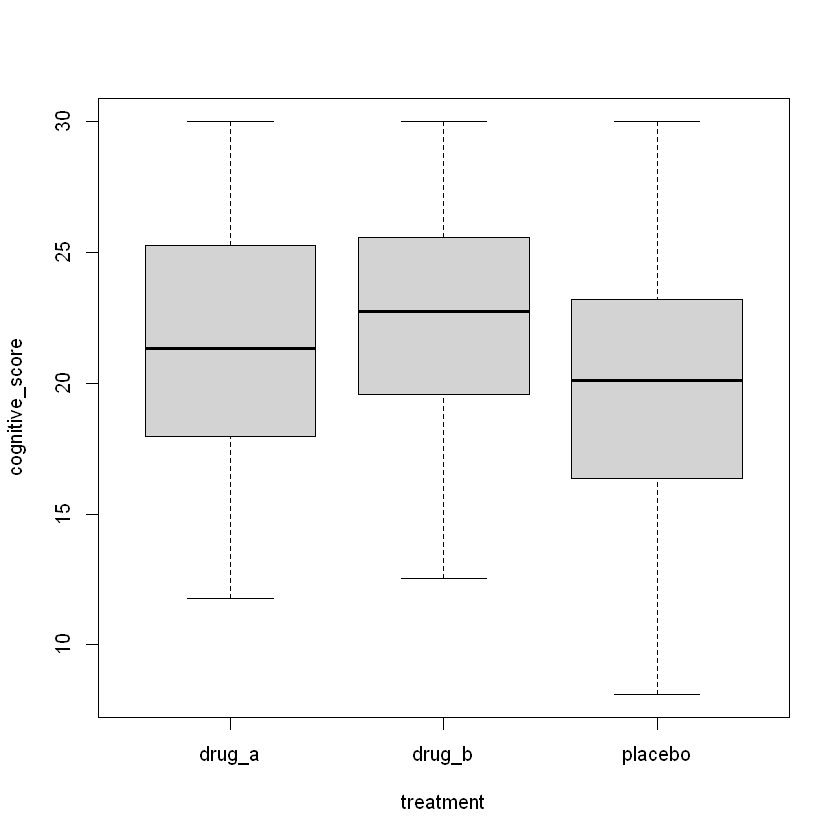

In [5]:
# Let's check graphically first
boxplot(cognitive_score ~ treatment, data = study)

# We want to perform an ANOVA1 before that we need to check the assumptions
# Normality -> 3 shapiro tests
# H0: the data follows a normal distribution
# H1: the data doesn't follow a normal distribution
shapiro.test(study$cognitive_score[study$treatment == "placebo"])
shapiro.test(study$cognitive_score[study$treatment == "drug_a"])
shapiro.test(study$cognitive_score[study$treatment == "drug_b"])

# All 3 treatments groups show p > alpha = 0.03, so we can't reject H0 and as such the distribution of all cognitive scores follow a normal distribution

# Homoscedasticity
bartlett.test(cognitive_score ~ treatment, data = study)
# We observe p = 0.017 < alpha = 0.03, so we reject H0 and as such the variances of the groups are different and we can't proceed to an ANOVA1
# Instead we can perform a Kruskal-Wallis test
# H0: The average cognitive scores across treatments are the same
# H1: At least one is different from the other
kruskal.test(cognitive_score ~ treatment, data = study)
# p = 0.004 <<< alpha = 0.03, as such we reject H0 and at least one average congitive score is different from the others
# To determine which we can perform a pairwise Mann-Whitney test
pairwise.wilcox.test(study$cognitive_score, study$treatment)
# It seems that placebo and drug B are mostly different
# As such, if any of the two drugs have an effect, it must be drug B

**Question 5**. (2 points)  
Perform a chi-square test of independence to examine the association between `treatment` and `apoe4_status`. What does the result suggest about the study design and randomization process?  

In [6]:
# Assumptions of chi²
# Theoretical counts >= 5
chisq.test(study$treatment, study$apoe4_status)$expected
# Hypotheses of chi² test
# H0: Treatment assignation is independent from number of APOE4 alleles
# H1: Treatment assignation isn't independent from number of APOE4 alleles
# Test
chisq.test(study$treatment, study$apoe4_status)

chisq.test(study$treatment, study$apoe4_status)$observed
# We observe p = 0.025 which is approximately equal to alpha, so we can't conclude clearly.
# This underline that may be the treatment assignation wasn't entirely random, or at least not random enough.
# We should change our assignation (or sub-sample our observed groups to achieve independence between these groups).

,0,1,2
drug_a,39.87940,15.26633,6.854271
drug_b,45.02513,17.23618,7.738693
placebo,43.09548,16.49749,7.407035



	Pearson's Chi-squared test

data:  study$treatment and study$apoe4_status
X-squared = 11.103, df = 4, p-value = 0.02543


               study$apoe4_status
study$treatment  0  1  2
        drug_a  36 17  9
        drug_b  41 24  5
        placebo 51  8  8

**Question 6**. (2 points)  
Calculate the correlation coefficient between `age` and `brain_volume`. Interpret the strength and direction of the relationship, and explain its relevance to Alzheimer's disease progression.

In [7]:
# Hypotheses of correlation test
# H0: There is no observed correlation between age and brain volume
# H1: The correlation is different from 0 between age and brain volume
cor.test(study$age, study$brain_volume)

# We observe p = 0.9 >>> alpha = 0.03, so we can't reject H0 and as such there is no correlation between age and brain volume.
# As such, brain volume seems independent from age, which, if brain volume is correlated with AD or AD's progression means the progression should be independent of age.
# It's also possible that brain volume is independent altogether of AD.


	Pearson's product-moment correlation

data:  study$age and study$brain_volume
t = 0.11481, df = 197, p-value = 0.9087
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 -0.1310595  0.1471021
sample estimates:
        cor 
0.008179548 


**Question 7**. (2 points)  
Create a scatter plot of `cognitive_score` vs. `age`. Describe the pattern you observe and discuss how it aligns with or differs from general expectations about cognitive decline in aging.
*Provide your code for this question*.


	Pearson's product-moment correlation

data:  study$age and study$cognitive_score
t = 0.14505, df = 197, p-value = 0.8848
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 -0.1289414  0.1492094
sample estimates:
      cor 
0.0103339 


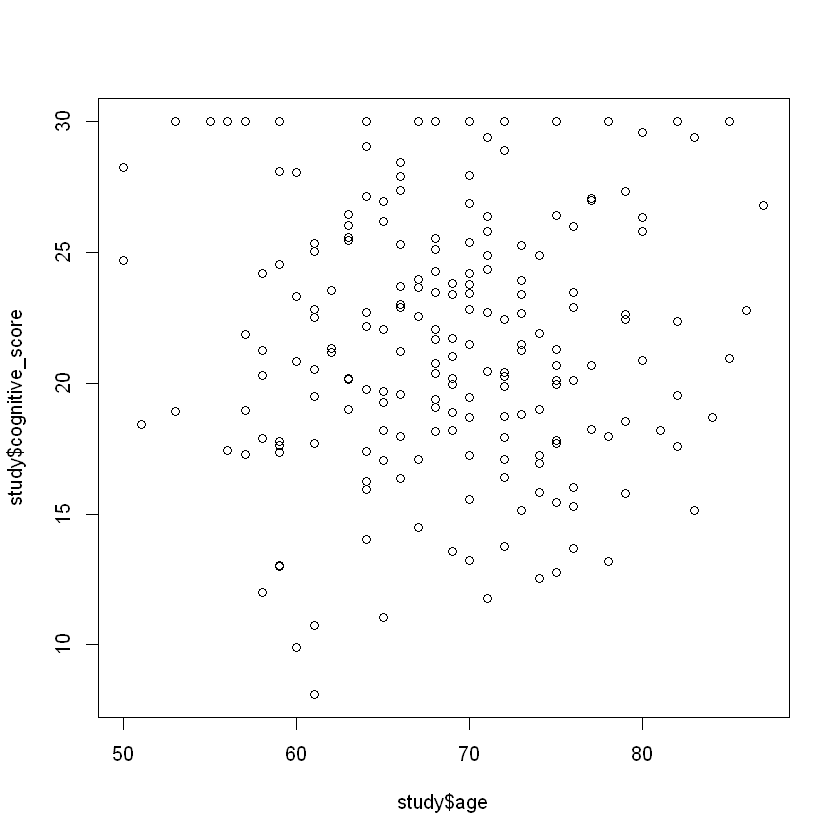

In [8]:
plot(study$age, study$cognitive_score)
cor.test(study$age, study$cognitive_score)

# We observe no clear correlation between age and cognitive score
# This seems contradictory with what is know with cognitive decline with aging.
# It may be a cohor effect?

**Question 8**. (2 points)  
Develop a simple linear regression model to predict `cognitive_score` based on `tau_protein`.  
Write the equation of the regression line and interpret what the slope and intercept mean in the context of Alzheimer's disease.  

In [12]:
tau_cs = lm(tau_protein ~ cognitive_score, data = study)
summary(tau_cs)

# The equation is cognitive score = -0.046 * tau_protein + 24.41
# This means that an increase in 1 (?) of tau protein decreases the cognitive score by 0.04 point.
# It doesn't seem much, but there is a clear effect.
# So the more tau protein accumulates in the brain, the less cognitively able is the patient


Call:
lm(formula = tau_protein ~ cognitive_score, data = study)

Residuals:
    Min      1Q  Median      3Q     Max 
-52.009 -10.030   2.171  11.026  41.865 

Coefficients:
                Estimate Std. Error t value Pr(>|t|)    
(Intercept)      73.8985     5.2864  13.979   <2e-16 ***
cognitive_score  -0.5360     0.2394  -2.239   0.0263 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 16.5 on 197 degrees of freedom
Multiple R-squared:  0.02481,	Adjusted R-squared:  0.01986 
F-statistic: 5.012 on 1 and 197 DF,  p-value: 0.02629


**Question 9**. (3 points)  
Conduct an analysis to determine if the effect of `treatment` on `cognitive_score` differs based on `apoe4_status`.  
Use appropriate statistical methods to test for this interaction effect. Interpret your results and discuss their implications for personalized treatment approaches in Alzheimer's disease. 

In [10]:
# We want to perform an ANOVA2 of the treatment and apoe4_staus on cognitive score
# Hypotheses
# H0: The avg cognitive scores don't differ by treatment
# H1: The avg cognitive scores differ by treatment
# H0': The avg cognitive scores don't differ by apoe4_status
# H1': The avg cognitive scores differ by apoe4 status
# H0'': The avg cognitive scores don't differ by interaction between treatment and apoe4_status
# H1'': The avg cognitive scores differ by interaction between treatment and apoe4_status

# Assumptions
# Normality & Homoscedasticity
shapiro.test(study$cognitive_score[study$treatment == "drug_a"  & study$apoe4_status == 0])
shapiro.test(study$cognitive_score[study$treatment == "drug_b"  & study$apoe4_status == 0])
shapiro.test(study$cognitive_score[study$treatment == "placebo" & study$apoe4_status == 0])
shapiro.test(study$cognitive_score[study$treatment == "drug_a"  & study$apoe4_status == 1])
shapiro.test(study$cognitive_score[study$treatment == "drug_b"  & study$apoe4_status == 1])
shapiro.test(study$cognitive_score[study$treatment == "placebo" & study$apoe4_status == 1])
shapiro.test(study$cognitive_score[study$treatment == "drug_a"  & study$apoe4_status == 2])
shapiro.test(study$cognitive_score[study$treatment == "drug_b"  & study$apoe4_status == 2])
shapiro.test(study$cognitive_score[study$treatment == "placebo" & study$apoe4_status == 2])
# All p > alpha = 0.03, all distributions are normal
study$group = paste(study$treatment, study$apoe4_status, sep = ".")
bartlett.test(cognitive_score ~ group, data = study)
# We observe p = 0.2 > alpha = 0.03, so we can't reject H0 and as such the variances are equal across groups
aov_cog = aov(cognitive_score ~ treatment * apoe4_status, data = study)

summary(aov_cog)
# We observe p <<< alpha for both treatment and apoe4 status, but not interaction
# It doesn't seem there is an interaction so it means that our treatments work whatever the number of APOE4 alleles.


	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "drug_a" & study$apoe4_status == 0]
W = 0.94113, p-value = 0.05509



	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "drug_b" & study$apoe4_status == 0]
W = 0.97878, p-value = 0.6294



	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "placebo" & study$apoe4_status == 0]
W = 0.97089, p-value = 0.2407



	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "drug_a" & study$apoe4_status == 1]
W = 0.95843, p-value = 0.6022



	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "drug_b" & study$apoe4_status == 1]
W = 0.94593, p-value = 0.2208



	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "placebo" & study$apoe4_status == 1]
W = 0.99026, p-value = 0.9955



	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "drug_a" & study$apoe4_status == 2]
W = 0.92072, p-value = 0.3983



	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "drug_b" & study$apoe4_status == 2]
W = 0.82445, p-value = 0.1263



	Shapiro-Wilk normality test

data:  study$cognitive_score[study$treatment == "placebo" & study$apoe4_status == 2]
W = 0.97794, p-value = 0.952



	Bartlett test of homogeneity of variances

data:  cognitive_score by group
Bartlett's K-squared = 10.883, df = 8, p-value = 0.2084


                        Df Sum Sq Mean Sq F value   Pr(>F)    
treatment                2    283  141.54   6.534 0.001796 ** 
apoe4_status             1    253  253.47  11.702 0.000762 ***
treatment:apoe4_status   2     30   15.19   0.701 0.497151    
Residuals              193   4181   21.66                     
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

**Question 10**. (2 points)  
Critically evaluate this study's design. Identify at least two limitations and propose how future studies could address these to improve our understanding of Alzheimer's disease progression and treatment.

Answer:

We have a problem with random treatment assignation which means treatments groups differ between their demographics
The following time of patients differs across groups
Even if the patients are followed longitudinally it seems we only one measure of each parameter, we should follow the efficiency of the treatment over long time.
We have no information about the treatment's administration, we should check how is it given and how it affects its effect.


## Bonus Questions
(1 point each, not counted in the main 20-point total)

These questions should be directly answered on the answer sheet!

**Bonus Question 1**. (1 point)  
Propose an additional biomarker or variable that could be included in future Alzheimer's disease studies. Explain how this variable might contribute to our understanding of the disease and its potential relationship with existing variables in the dataset.  

Answer: Could many things. Additional biomarkers of health of many systems: inflammation markers, epigenetics ones, sleep patterns, etc. or lifestyle factors. Any well justified marker could be accepted

**Bonus Question 2**. (1 point)  
In the context of Alzheimer's disease research, explain the importance of longitudinal studies compared to cross-sectional studies. How might the conclusions drawn from each type of study differ?  

Answer: Longitudinal study follow patients over long time and can see repeated measures while cross sectional are one shot. following patients over time can uncover systemic effects.